In [1]:
# ===============================
# import libraries
# ===============================
import re
from pathlib import Path

import chartgazing as cg
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib import patheffects
from matplotlib.patches import Circle
from matplotlib.ticker import FuncFormatter

cg.set_size("4:5")

In [2]:
# ===============================
# import data
# ===============================

# set data directory
DATA_DIR = Path("data/sets")

# combine every saved set
pokemon_all = pd.concat(
    [pd.read_csv(path, dtype={"number": str, "product_id": str, "variant": str}, parse_dates=["date"]) for path in DATA_DIR.glob("*.csv")],
    ignore_index=True
)

# additional data on each set
sets_df = pd.read_csv("data/sets_info.csv", parse_dates=["release_date"])
pokemon_all = pokemon_all.merge(sets_df, on="set_slug", how="left")

In [3]:
# ===============================
# clean data
# ===============================
pokemon_all["variant"] = pokemon_all["variant"].fillna("Standard")
pokemon_all["price"] = pokemon_all["price"].replace(0, np.nan)
pokemon_all["date"] = pokemon_all["date"].dt.to_period("M").dt.to_timestamp()
pokemon_all["decade"] = (pokemon_all["release_date"].dt.year // 10) * 10


for col in ["grade", "set_slug", "set_name", "language", "name", "variant"]:
    pokemon_all[col] = pokemon_all[col].astype("category")

In [4]:
# ===============================
# shared data for the charts
# ===============================
GRADE = "Ungraded"
IMAGE_DIR = Path("images/4x5")
source = "Source: PriceCharting."

all_prices = pokemon_all.dropna(subset=["price"])
priced_cards = all_prices[all_prices["grade"] == GRADE]
latest_date = priced_cards["date"].max()
latest_cards = priced_cards[priced_cards["date"] == latest_date]


def fmt(value):
    """$1,234 for large prices, $12.34 for small ones."""
    return f"${value:,.0f}" if value >= 1000 else f"${value:,.2f}"


def short_set(set_name):
    return set_name.removeprefix("Pokemon ")


def one_per_card(cards):
    """Variants of a card (reverse holo, 1st edition...) share a set, number and name, so keep one:
    the standard version, or the cheapest version where there is no standard version."""
    return (
        cards.assign(not_standard=cards["variant"] != "Standard")
        .sort_values(["not_standard", "price"])
        .drop_duplicates(["set_slug", "number", "name"])
    )


# from chartgazing templates/26_bar_labelled.py
def label_bars(ax, bars, values, horizontal=True, inside_share=0.15, highlight_index=None):
    """Write each value inside its bar if the bar is long enough, otherwise just past the end."""
    longest = max(values)
    for i, (bar, v) in enumerate(zip(bars, values)):
        inside = v >= inside_share * longest
        colour = cg.text_on(bar.get_facecolor()) if inside else cg.TEXT
        weight = "bold" if i == highlight_index else "normal"
        if horizontal:
            x, y = bar.get_width(), bar.get_y() + bar.get_height() / 2
            ax.annotate(fmt(v), (x, y), xytext=(-4 if inside else 3, 0), textcoords="offset points",
                        ha="right" if inside else "left", va="center", fontsize=7.5, color=colour,
                        fontweight=weight)
        else:
            x, y = bar.get_x() + bar.get_width() / 2, bar.get_height()
            ax.annotate(fmt(v), (x, y), xytext=(0, -4 if inside else 3), textcoords="offset points",
                        ha="center", va="top" if inside else "bottom", fontsize=7.5, color=colour,
                        fontweight=weight)

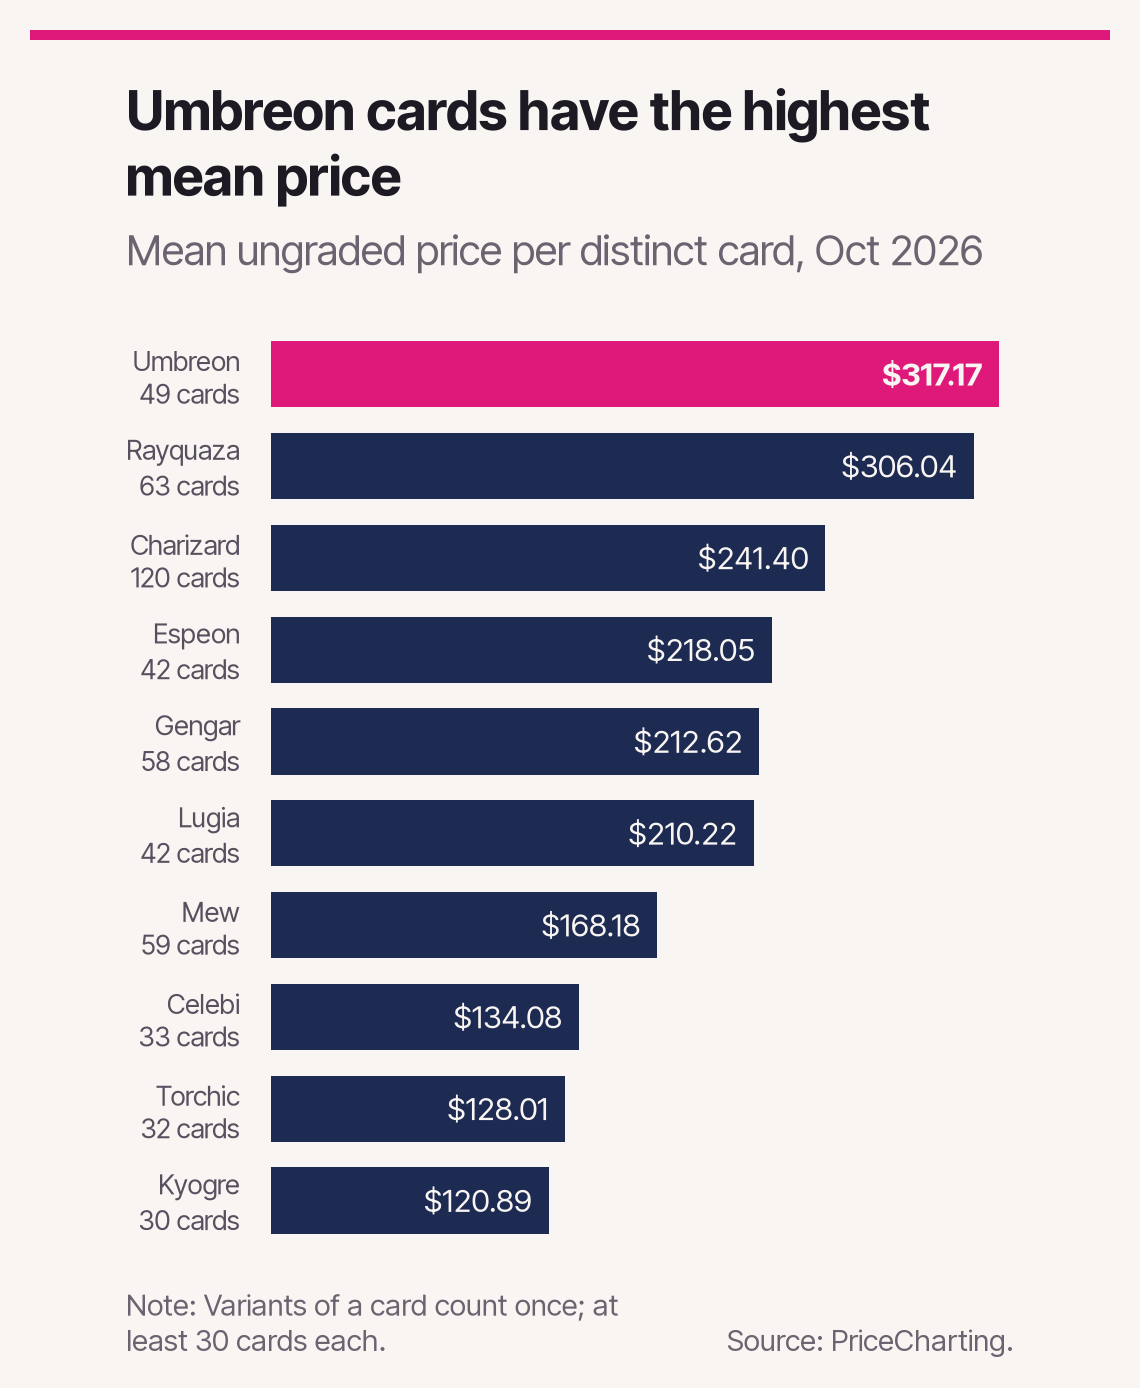

In [5]:
# ===============================
# top 10 pokemon by mean card price (template: 26_bar_labelled)
# ===============================
TOP_N = 10
MIN_CARDS = 30  # leaves out trainer and item cards, and pokemon with only a handful of cards

# owner and form words either side of the pokemon, e.g. "blaine's charizard", "m charizard ex"
NAME_PREFIX = r"^(?:.*?'s |dark |light |shining |radiant |mega |m |galarian |alolan |hisuian |paldean |special delivery |trapped )+"
NAME_SUFFIX = r"(?: (?:ex|gx|v|vmax|vstar|v-union|break|lv\.? ?x|prime|legend|star|g|gl|c|fb|4|e4|sp|spirit link|x|y)(?: |$))+.*$"


def pokemon_from_name(name):
    return re.sub(NAME_SUFFIX, "", re.sub(NAME_PREFIX, "", name)).strip()


# tag team cards ("reshiram & charizard gx") belong to more than one pokemon, so they're left out
single_pokemon = latest_cards[~latest_cards["name"].astype(str).str.contains("&")]

distinct_cards = one_per_card(single_pokemon)
distinct_cards = distinct_cards.assign(pokemon=distinct_cards["name"].astype(str).map(pokemon_from_name))

top_pokemon = (
    distinct_cards.groupby("pokemon")["price"]
    .agg(["mean", "count"])
    .query("count >= @MIN_CARDS")
    .nlargest(TOP_N, "mean")
    .iloc[::-1]          # barh draws bottom-up
)
highlight = top_pokemon.index[-1]

fig, ax = cg.chart(
    f"{highlight.title()} cards have the highest mean price",
    f"Mean {GRADE.lower()} price per distinct card, {latest_date:%b %Y}",
    note=f"Note: Variants of a card count once; at least {MIN_CARDS} cards each.",
    source=source,
    grid=None,
)
labels = [f"{name.title()}\n{count} cards" for name, count in zip(top_pokemon.index, top_pokemon["count"])]
colours = [cg.PRIMARY if name == highlight else cg.SECONDARY for name in top_pokemon.index]
bars = ax.barh(labels, top_pokemon["mean"], color=colours, height=0.72)
label_bars(ax, bars, top_pokemon["mean"].to_numpy(), highlight_index=len(top_pokemon) - 1)
ax.set_xticks([])
ax.tick_params(axis="y", labelsize=6.5, pad=4)
plt.setp(ax.get_yticklabels(), linespacing=1)
ax.margins(x=0.02, y=0.02)

cg.save(fig, IMAGE_DIR / "top_pokemon_mean_price.png")
plt.show()

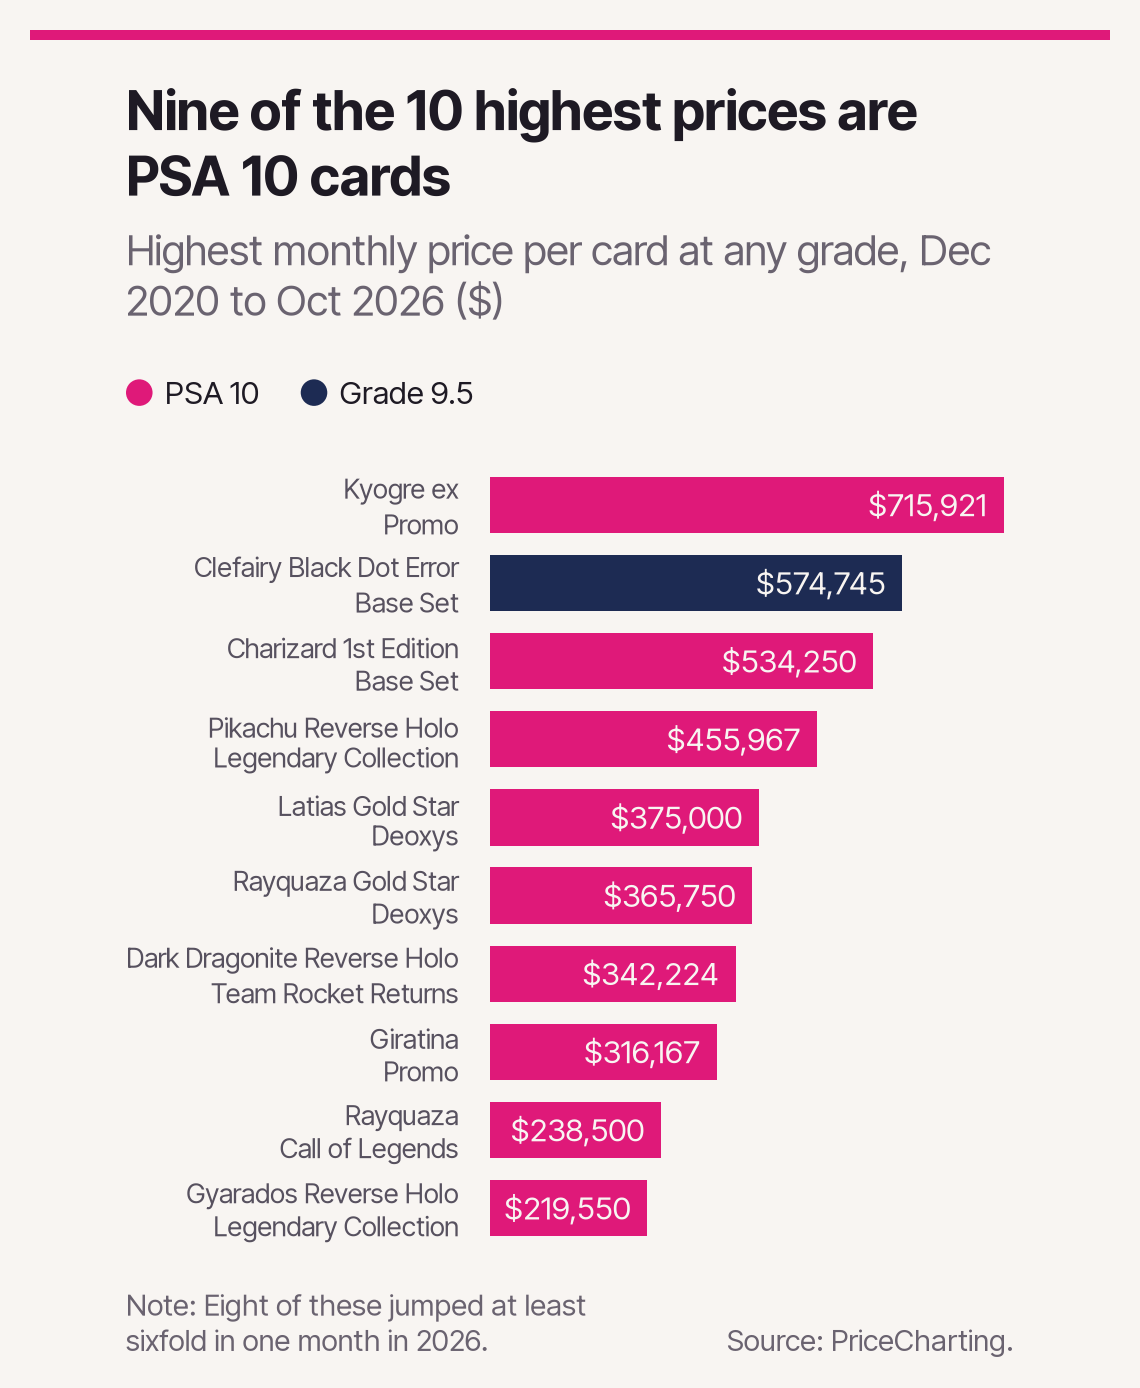

In [6]:
# ===============================
# top 10 highest priced cards of all time, by grade (template: 26_bar_labelled)
# ===============================
# each card appears once, at the grade and month of its highest price
top_cards = (
    all_prices.sort_values("price", ascending=False)
    .drop_duplicates("product_id")
    .head(10)
    .iloc[::-1]          # barh draws bottom-up
)

# colour follows the grade, whichever grades make the top 10
grade_colours = dict(zip(["PSA 10", "Grade 9.5", "Grade 9", "Grade 8", "Grade 7", "Ungraded"], cg.PALETTE))
top_grades = top_cards["grade"].astype(str)


def top_card_label(card):
    version = "" if card["variant"] == "Standard" else f" {card['variant']}"
    return f"{str(card['name']).title().replace(' Ex', ' ex')}{version}\n{short_set(str(card['set_name']))}"


fig, ax = cg.chart(
    "Nine of the 10 highest prices are PSA 10 cards",
    f"Highest monthly price per card at any grade, {all_prices['date'].min():%b %Y} to {latest_date:%b %Y} ($)",
    note="Note: Eight of these jumped at least sixfold in one month in 2026.",
    source=source,
    grid=None,
)
y = range(len(top_cards))
bars = ax.barh(y, top_cards["price"], color=top_grades.map(grade_colours), height=0.72)
label_bars(ax, bars, top_cards["price"].to_numpy())
ax.set_yticks(y, top_cards.apply(top_card_label, axis=1), fontsize=6.5, linespacing=1)
ax.set_xticks([])
ax.tick_params(axis="y", pad=4)
ax.margins(x=0.02, y=0.02)
cg.key(ax, {grade: colour for grade, colour in grade_colours.items() if grade in set(top_grades)})

cg.save(fig, IMAGE_DIR / "top_10_highest_prices.png")
plt.show()

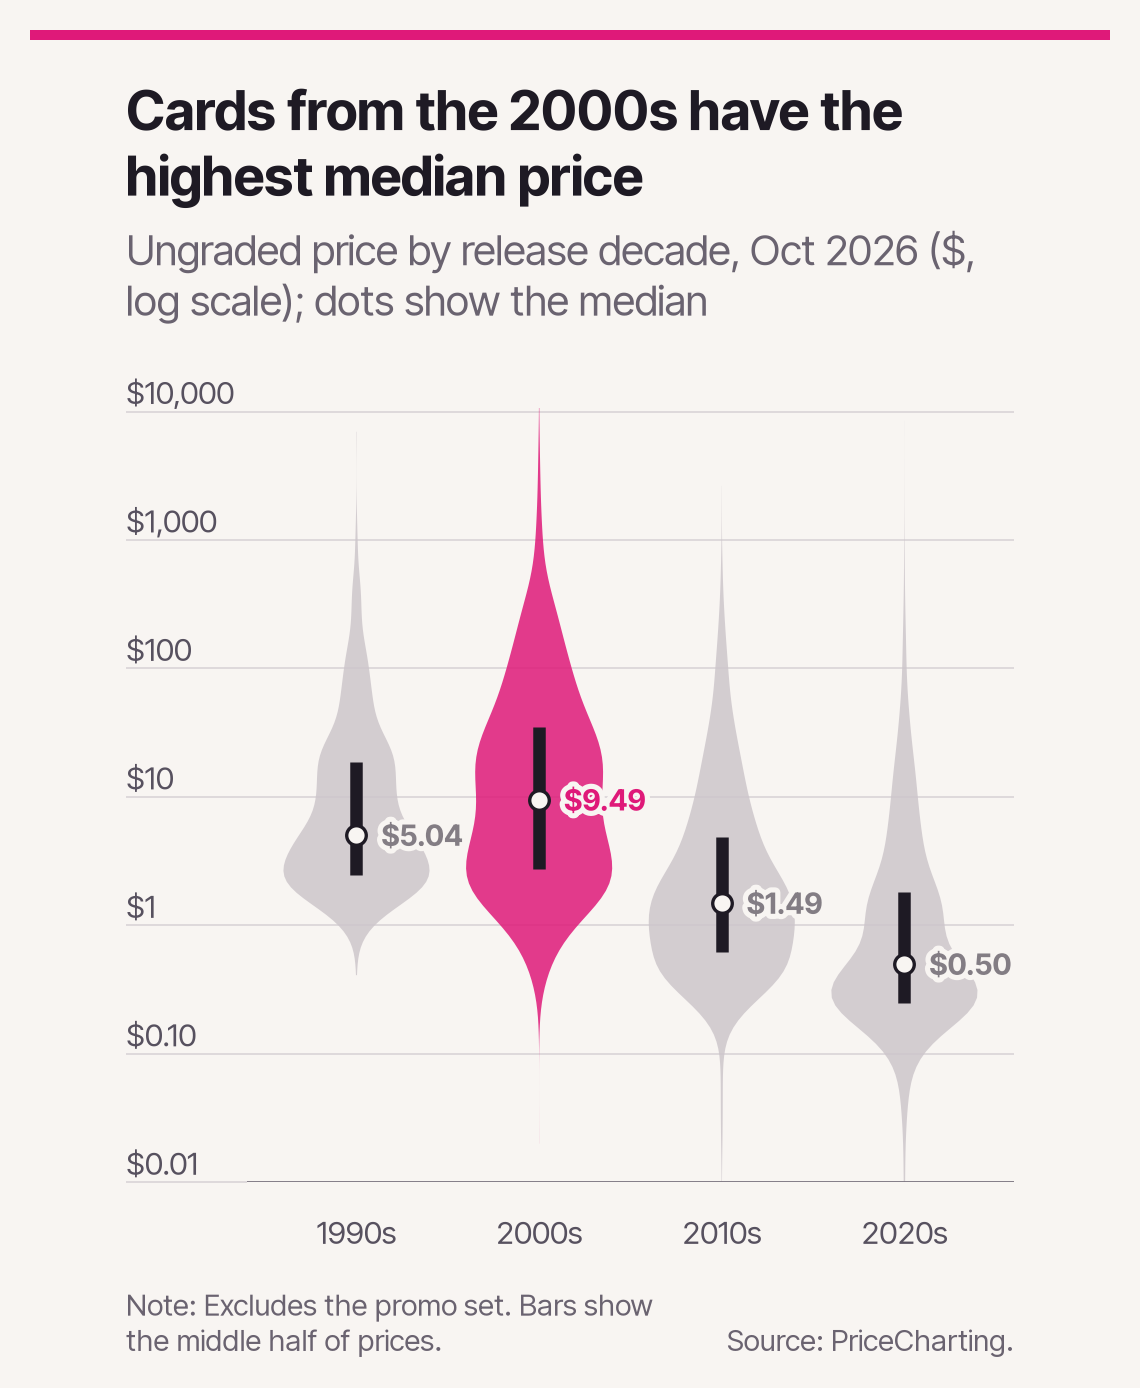

In [7]:
# ===============================
# violin plot of price by decade (template: 30_violin)
# ===============================
# every card in the promo set shares one release date (2016), so it can't be split by decade
decade_cards = latest_cards[~latest_cards["promo"]]
order = sorted(decade_cards["decade"].unique())

colors = {2000: cg.PRIMARY}  # any decade left out is drawn in cg.NEUTRAL
bandwidth = 0.25             # smoothing: smaller shows more detail, larger is smoother
fill_alpha = 0.85

halo = [patheffects.withStroke(linewidth=2.5, foreground=cg.BACKGROUND)]


def inner(ax, x, values, color):
    """The middle-half bar, the median dot and its label, for one violin at x."""
    q1, median, q3 = np.percentile(values, [25, 50, 75])
    ax.vlines(x, q1, q3, color=cg.TEXT, linewidth=3, zorder=3)
    ax.scatter(x, median, s=22, color=cg.BACKGROUND, edgecolor=cg.TEXT, linewidth=0.8, zorder=4)
    ax.annotate(fmt(10.0 ** median), xy=(x, median), xytext=(6, 0), textcoords="offset points",
                ha="left", va="center", fontsize=7, fontweight="bold", color=cg.ink(color), zorder=5,
                path_effects=halo)


# drawn in log10 units: prices run from a few cents to thousands of dollars
groups = [np.log10(decade_cards.loc[decade_cards["decade"] == d, "price"]).to_numpy() for d in order]

fig, ax = cg.chart(
    "Cards from the 2000s have the highest median price",
    f"{GRADE} price by release decade, {latest_date:%b %Y} ($, log scale); dots show the median",
    note="Note: Excludes the promo set. Bars show the middle half of prices.",
    source=source,
    grid="y",
)

parts = ax.violinplot(groups, positions=range(len(order)), widths=0.8, showextrema=False,
                      bw_method=bandwidth)
for body, decade in zip(parts["bodies"], order):
    body.set_facecolor(colors.get(decade, cg.NEUTRAL))
    body.set_edgecolor("none")
    body.set_alpha(fill_alpha)
for x, (values, decade) in enumerate(zip(groups, order)):
    inner(ax, x, values, colors.get(decade, cg.NEUTRAL))

ax.set_xticks(range(len(order)), [f"{d}s" for d in order])
ax.set_xlim(-0.6, len(order) - 0.4)
ax.set_yticks(range(-2, 5))
ax.set_ylim(-2, 4.2)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"${10.0 ** v:,.2f}" if v < 0 else f"${10.0 ** v:,.0f}"))
cg.baseline(ax, y=-2)

cg.save(fig, IMAGE_DIR / "price_by_decade_violin.png")
plt.show()

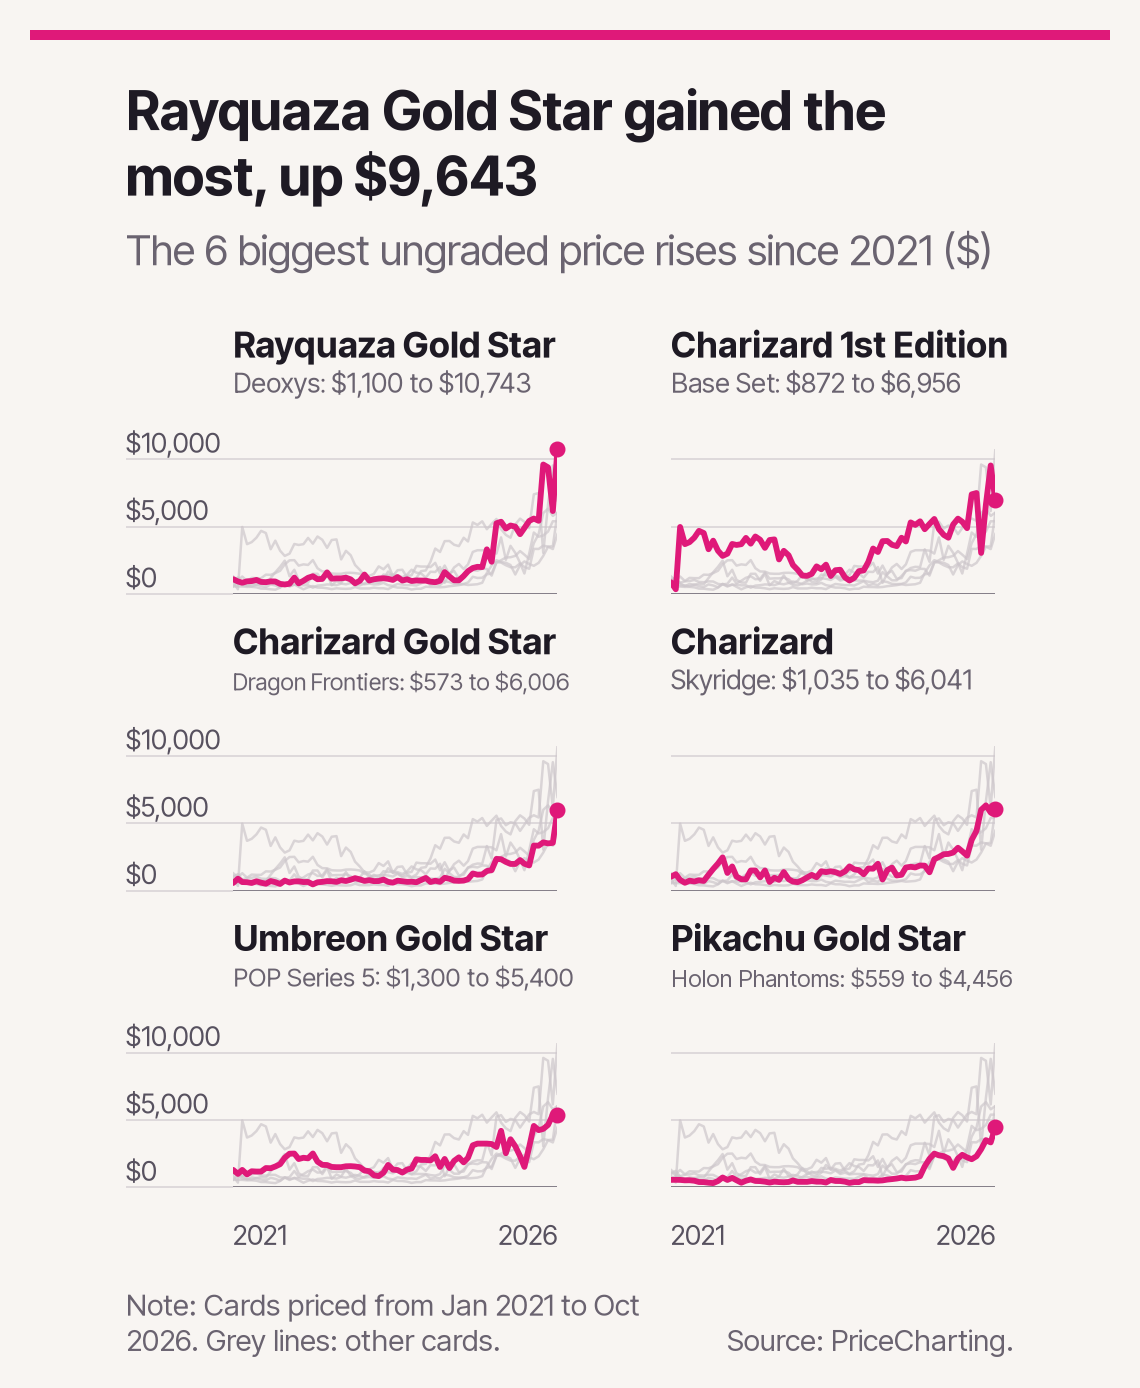

In [8]:
# ===============================
# 6 cards with the highest price increase (template: 13_small_multiples)
# ===============================
# cards priced from the start of the data and still priced now, so every card covers the same period
START_BY = "2021-01-01"

price_change = priced_cards.sort_values("date").groupby("product_id", observed=True).agg(
    first_date=("date", "first"),
    last_date=("date", "last"),
    first_price=("price", "first"),
    last_price=("price", "last"),
    name=("name", "first"),
    variant=("variant", "first"),
)
price_change = price_change[(price_change["first_date"] <= START_BY) & (price_change["last_date"] == latest_date)]
price_change["increase"] = price_change["last_price"] - price_change["first_price"]
top_increases = price_change.nlargest(6, "increase")


def card_label(card):
    return f"{card['name'].title()} {card['variant']}" if card["variant"] != "Standard" else card["name"].title()


top_increases["card"] = top_increases.apply(card_label, axis=1)

PANEL, X, Y = "card", "date", "price"
df = (
    priced_cards[priced_cards["product_id"].isin(top_increases.index)]
    .sort_values(X)
    .assign(card=lambda d: d["product_id"].map(top_increases["card"]))
)
first, last = df[X].min(), df[X].max()


def end_ticks(ax):
    """Show only the first and last x value, kept inside the panel."""
    ax.set_xlim(first, last)
    ax.set_xticks([first, last], [first.year, last.year])
    ticks = ax.xaxis.get_major_ticks()
    ticks[0].label1.set_horizontalalignment("left")
    ticks[-1].label1.set_horizontalalignment("right")
    ax.tick_params(labelsize=6.5)


def draw(ax, group, key):
    for other, g in df[df[PANEL] != key].groupby(PANEL):
        ax.plot(g[X], g[Y], color=cg.NEUTRAL, linewidth=0.6, alpha=0.7)
    ax.plot(group[X], group[Y], color=cg.PRIMARY, linewidth=1.4, solid_capstyle="round")
    ax.scatter(group[X].iloc[-1], group[Y].iloc[-1], s=8, color=cg.PRIMARY, zorder=3, clip_on=False)
    end_ticks(ax)
    ax.set_ylim(0, 11000)
    ax.set_yticks(range(0, 10001, 5000))
    cg.number_axis(ax.yaxis, prefix="$")
    cg.baseline(ax)


# the dollar signs are escaped because matplotlib reads a pair of them as maths text
fig, axes = cg.facet_wrap(
    df, PANEL, draw, order=top_increases["card"].tolist(),
    ncols=2, sharex=True, sharey=True, wspace=0.35, hspace=1.05,
    title="Rayquaza Gold Star gained the most, up $9,643",
    subtitle=f"The 6 biggest {GRADE.lower()} price rises since {first.year} ($)",
    note=f"Note: Cards priced from {pd.Timestamp(START_BY):%b %Y} to {latest_date:%b %Y}. Grey lines: other cards.",
    source=source,
    panel_subtitle=lambda g, k: f"{short_set(str(g['set_name'].iloc[0]))}: \\${g[Y].iloc[0]:,.0f} to \\${g[Y].iloc[-1]:,.0f}",
)

cg.save(fig, IMAGE_DIR / "biggest_price_increases.png")
plt.show()

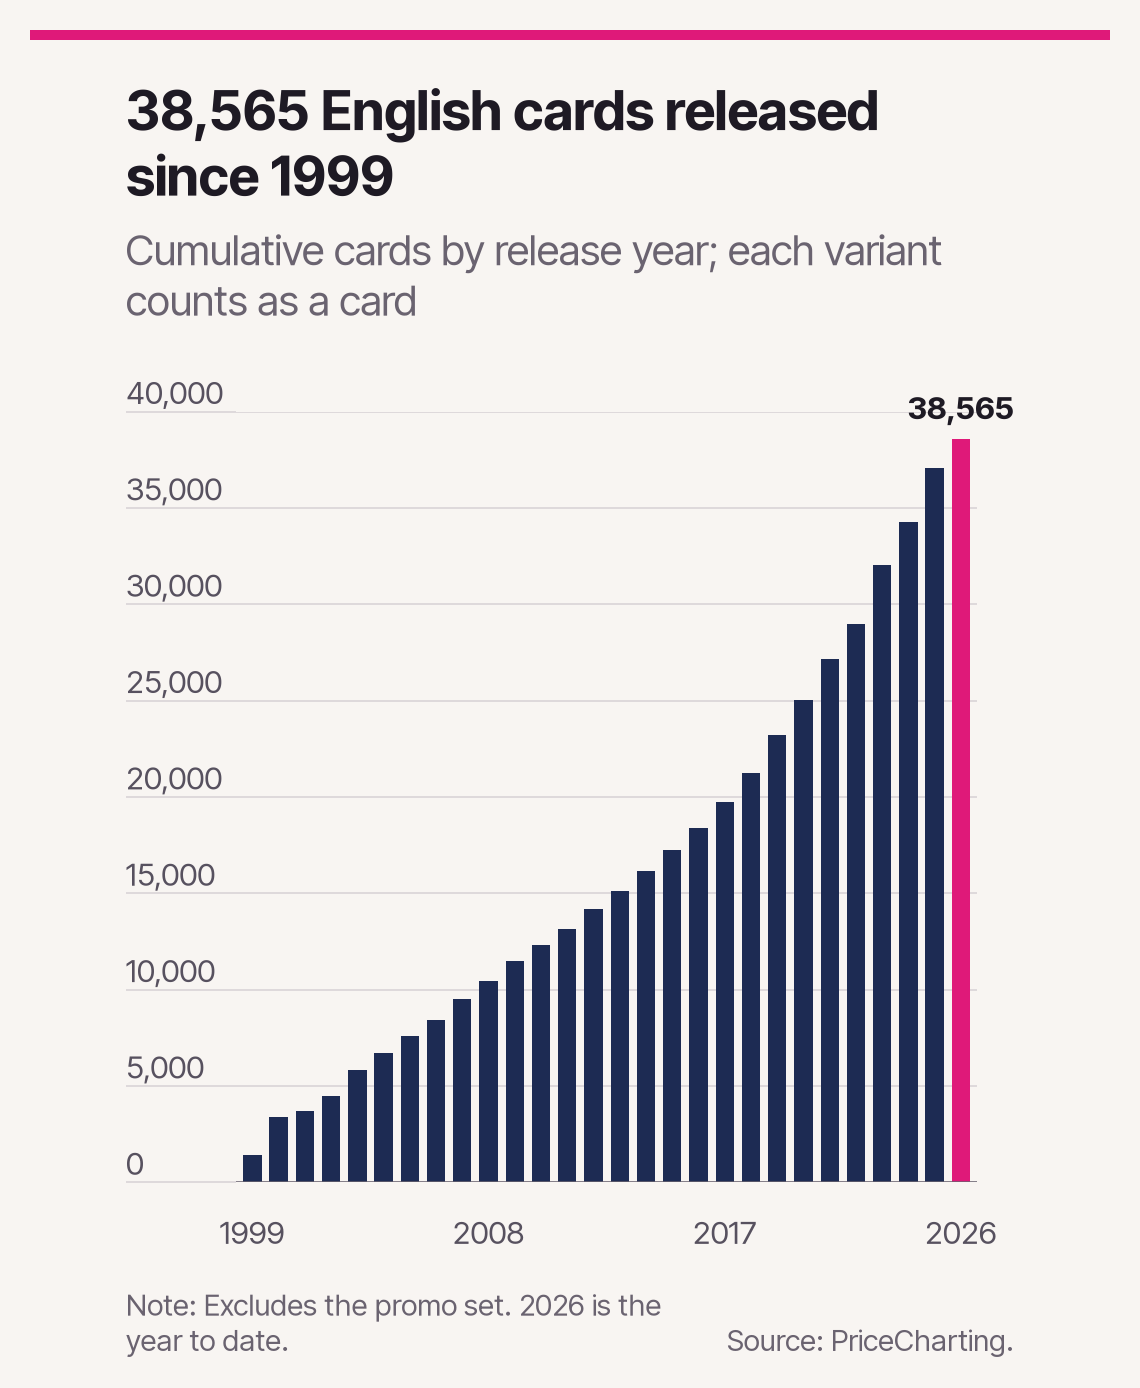

In [9]:
# ===============================
# cumulative cards released per year (template: 02_bar, columns over time)
# ===============================
# every card in the promo set shares one release date (2016), which would look like a jump that year
released_cards = pokemon_all.loc[~pokemon_all["promo"], ["product_id", "release_date"]].drop_duplicates("product_id")
released_per_year = released_cards.groupby(released_cards["release_date"].dt.year).size()
series = released_per_year.cumsum()

fig, ax = cg.chart(
    f"{series.iloc[-1]:,} English cards released since {series.index[0]}",
    "Cumulative cards by release year; each variant counts as a card",
    note=f"Note: Excludes the promo set. {series.index[-1]} is the year to date.",
    source=source,
    grid="y",
)

colors = [cg.PRIMARY if p == series.index[-1] else cg.SECONDARY for p in series.index]
ax.bar(series.index, series.values, color=colors, width=0.7)

ax.annotate(f"{series.iloc[-1]:,.0f}", xy=(series.index[-1], series.iloc[-1]),
            xytext=(0, 3), textcoords="offset points", ha="center", va="bottom",
            fontsize=7.5, fontweight="bold", color=cg.TEXT)

ax.set_xticks(series.index[::9])
ax.margins(x=0.01)
cg.number_axis(ax.yaxis)
cg.baseline(ax)

cg.save(fig, IMAGE_DIR / "cumulative_cards_released.png")
plt.show()

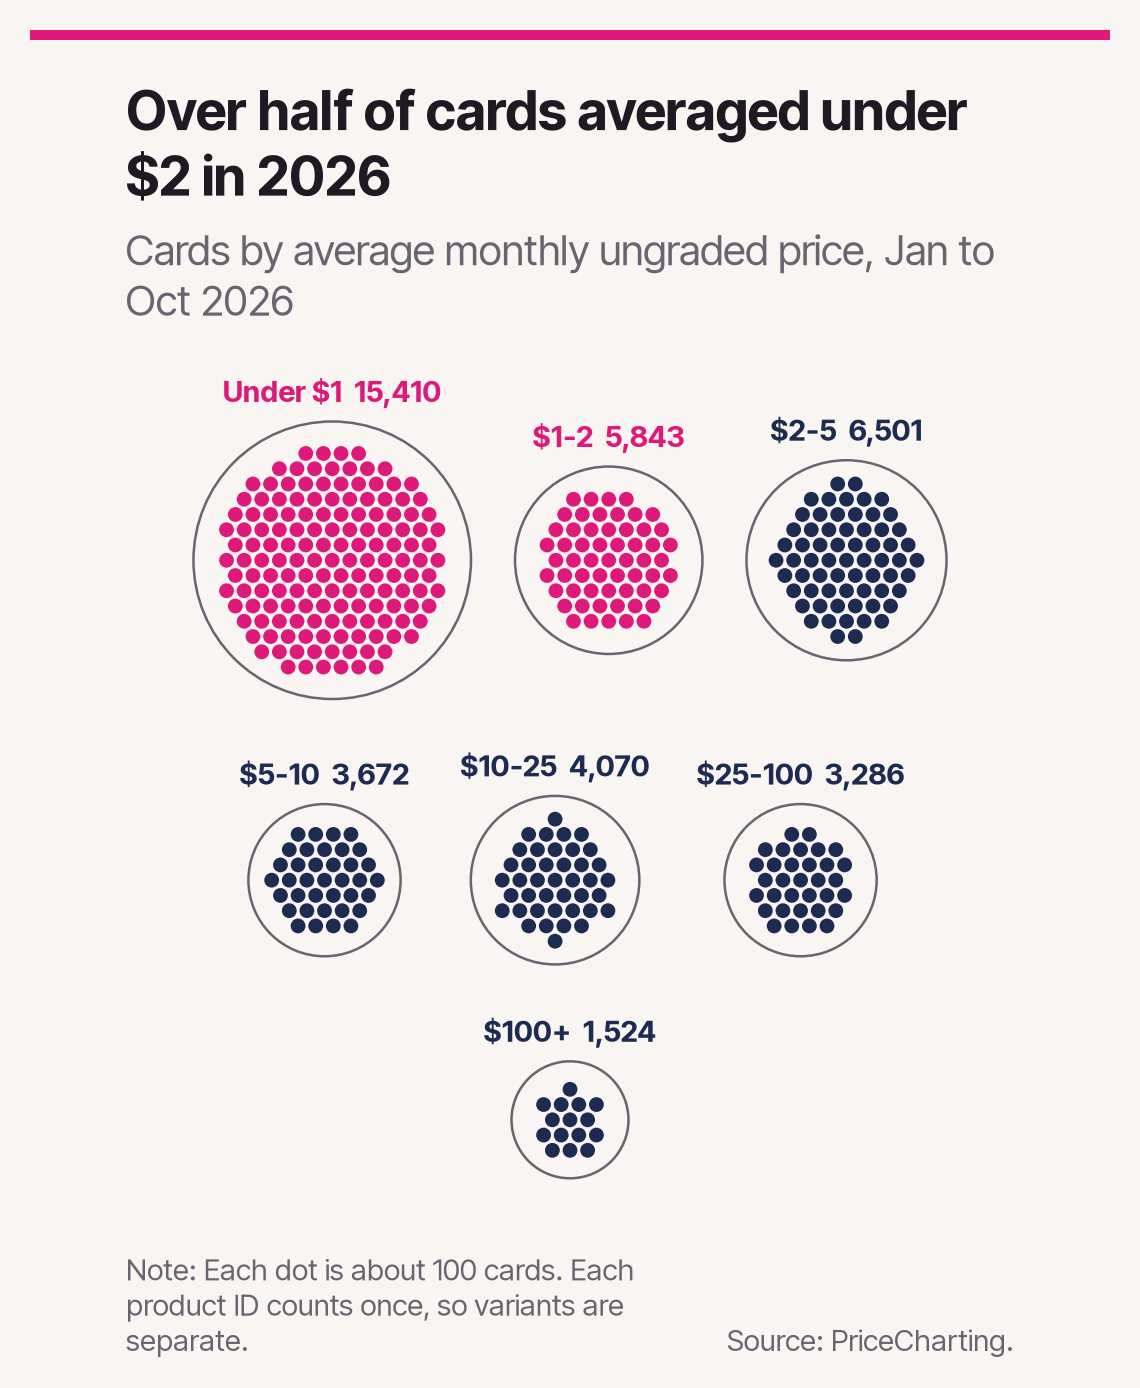

In [10]:
# ===============================
# cards by price bucket (template: 34_grouped_dots)
# ===============================
GROUP, COUNT = "bucket", "cards"
BUCKET_YEAR = 2026
CARDS_PER_DOT = 100  # the template draws one dot per item, which is too many for this many cards

year_prices = priced_cards[priced_cards["date"].dt.year == BUCKET_YEAR]
card_prices = year_prices.groupby("product_id")["price"].mean()

BUCKET_EDGES = [0, 1, 2, 5, 10, 25, 100, np.inf]
BUCKET_LABELS = ["Under $1", "$1-2", "$2-5", "$5-10", "$10-25", "$25-100", "$100+"]
df = (
    pd.cut(card_prices, BUCKET_EDGES, labels=BUCKET_LABELS, right=False)
    .value_counts(sort=False)
    .rename_axis(GROUP)
    .reset_index(name=COUNT)
)
df[GROUP] = df[GROUP].astype(str)

colors = {g: cg.PRIMARY if g in BUCKET_LABELS[:2] else cg.SECONDARY for g in df[GROUP]}

title = "Over half of cards averaged under $2 in 2026"
subtitle = f"Cards by average monthly {GRADE.lower()} price, {year_prices['date'].min():%b} to {latest_date:%b %Y}"
note = f"Note: Each dot is about {CARDS_PER_DOT} cards. Each product ID counts once, so variants are separate."

DOT = 0.42           # dot radius, where 1 is the distance between neighbouring dots
PAD = 0.9            # space between a cluster's outer dots and its circle
GAP = 2.5            # space between circles
LABEL = 3.0          # room above each circle for its label


def hex_cluster(n):
    """Centres of n dots in a hexagonal grid, the n closest to the middle: a roughly round cluster."""
    k = int(np.ceil(np.sqrt(n))) + 2
    rows, cols = np.meshgrid(np.arange(-k, k + 1), np.arange(-k, k + 1), indexing="ij")
    x = (cols + 0.5 * (rows % 2)).ravel()
    y = (rows * np.sqrt(3) / 2).ravel()
    nearest = np.argsort(x ** 2 + y ** 2, kind="stable")[:n]
    return x[nearest], y[nearest]


def flow(radii, slots, width):
    """Centres for circles laid out in rows, left to right, wrapping at `width`. Each circle takes a
    slot at least as wide as its label; rows are centred and leave LABEL room above for labels."""
    rows, row, used = [], [], 0
    for r, slot in zip(radii, slots):
        if row and used + slot > width:
            rows.append(row)
            row, used = [], 0
        row.append((r, slot))
        used += slot + GAP
    rows.append(row)
    centres, top = [], 0.0
    for row in rows:
        height = 2 * max(r for r, _ in row)
        x = -(sum(slot for _, slot in row) + GAP * (len(row) - 1)) / 2
        for r, slot in row:
            centres.append((x + slot / 2, top - LABEL - height / 2))
            x += slot + GAP
        top -= LABEL + height + GAP
    return centres


def grouped_dots(ax, df, colors):
    """Draw the clusters in rows shaped to fit the plot. Unlike the template, they stay in the order
    of df (here cheapest first) rather than biggest first, because the buckets have an order."""
    clusters = {g: hex_cluster(round(n / CARDS_PER_DOT)) for g, n in zip(df[GROUP], df[COUNT])}
    radii = [np.sqrt(x ** 2 + y ** 2).max() + DOT + PAD for x, y in clusters.values()]
    # try row widths and keep the one whose overall shape is closest to the plot area's
    w_in, h_in = ax.figure.get_size_inches()
    target = (w_in - 0.8) / (h_in - 1.4)                   # roughly the plot area under the header
    best = None
    labels = [f"{g}  {n:,}" for g, n in zip(df[GROUP], df[COUNT])]
    for width in np.linspace(max(radii) * 2, sum(2 * r + GAP for r in radii) * 1.6, 60):
        points_per_unit = (w_in - 0.8) * 72 / width          # if the layout fills the width
        slots = [max(2 * r, len(text) * 7 * 0.56 / points_per_unit) for r, text in zip(radii, labels)]
        centres = flow(radii, slots, width)
        xs = [x + s * w / 2 for (x, _), w in zip(centres, slots) for s in (-1, 1)]
        ys = [y + s * r for (_, y), r in zip(centres, radii) for s in (-1, 1)] + [0]
        shape = (max(xs) - min(xs)) / (max(ys) - min(ys))
        if best is None or abs(np.log(shape / target)) < best[0]:
            best = (abs(np.log(shape / target)), centres)
    for (group, (dx, dy)), (cx, cy), r in zip(clusters.items(), best[1], radii):
        color = colors[group]
        ax.add_patch(Circle((cx, cy), r, facecolor="none", edgecolor=cg.MUTED, linewidth=0.6))
        for x, y in zip(dx, dy):
            ax.add_patch(Circle((cx + x, cy + y), DOT, facecolor=color, edgecolor="none"))
        n = int(df.loc[df[GROUP] == group, COUNT].iloc[0])
        ax.annotate(f"{group}  {n:,}", xy=(cx, cy + r), xytext=(0, 3), textcoords="offset points",
                    ha="center", va="bottom", fontsize=7, fontweight="bold", color=cg.ink(color))
    ax.autoscale_view()
    ax.set_aspect("equal")
    ax.set_axis_off()


fig, ax = cg.chart(title, subtitle, note=note, source=source, grid=None)
grouped_dots(ax, df, colors)
cg.save(fig, IMAGE_DIR / "card_price_buckets_grouped_dots.png", sides="tb")
plt.show()

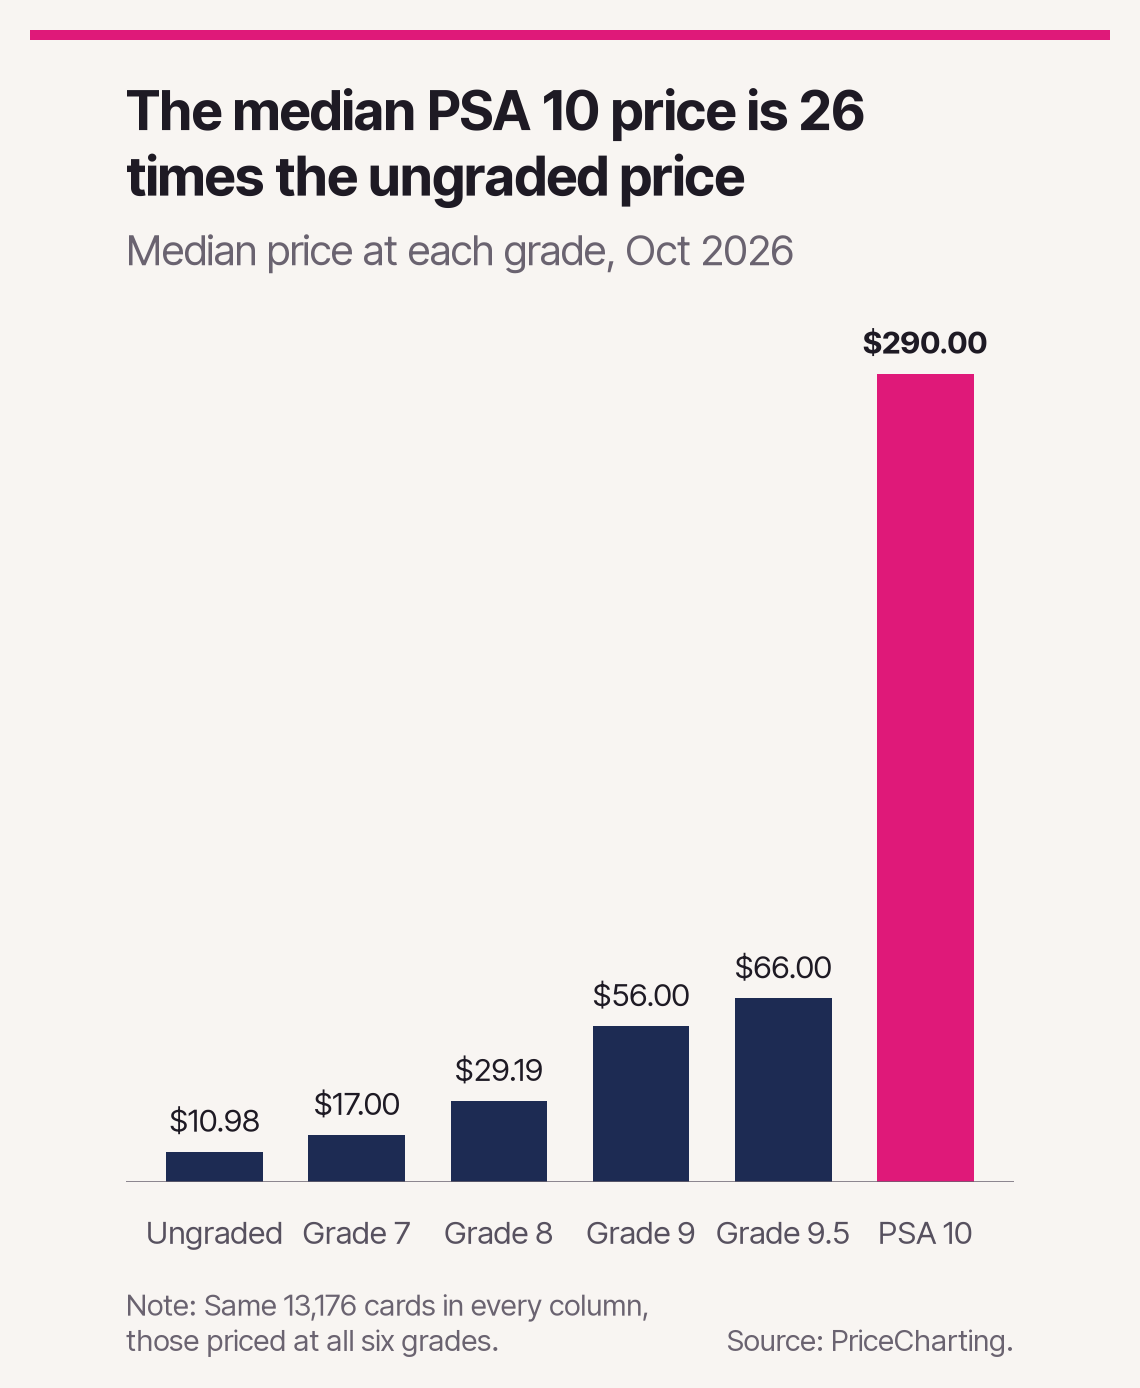

In [11]:
# ===============================
# price by grade, ungraded up to PSA 10 (template: 26_bar_labelled, columns)
# ===============================
GRADE_ORDER = ["Ungraded", "Grade 7", "Grade 8", "Grade 9", "Grade 9.5", "PSA 10"]

# only cards priced at every grade, so each column compares the same cards. Without this, the mix
# of cards changes from grade to grade: Grade 9 comes out cheaper than Grade 8
latest_all_grades = all_prices[all_prices["date"] == latest_date]
grade_prices = (
    latest_all_grades.pivot_table(index="product_id", columns="grade", values="price", observed=True)[GRADE_ORDER]
    .dropna()
)
grade_medians = grade_prices.median()
times_ungraded = grade_medians["PSA 10"] / grade_medians["Ungraded"]

fig, ax = cg.chart(
    f"The median PSA 10 price is {times_ungraded:.0f} times the ungraded price",
    f"Median price at each grade, {latest_date:%b %Y}",
    note=f"Note: Same {len(grade_prices):,} cards in every column, those priced at all six grades.",
    source=source,
    grid=None,
)
colours = [cg.PRIMARY if grade == "PSA 10" else cg.SECONDARY for grade in GRADE_ORDER]
bars = ax.bar(GRADE_ORDER, grade_medians, color=colours, width=0.68)
label_bars(ax, bars, grade_medians.to_numpy(), horizontal=False, inside_share=1.01,  # all above the columns
           highlight_index=len(GRADE_ORDER) - 1)
ax.set_yticks([])
ax.margins(y=0.02)
cg.baseline(ax)

cg.save(fig, IMAGE_DIR / "price_by_grade.png")
plt.show()

In [12]:
# ===============================
# gained or lost value in 2026 (template: 03_stacked_bar, cg.stacked_bar)
# ===============================
START_DATE = pd.Timestamp("2026-01-01")
CHANGE_ORDER = ["Gained", "Unchanged", "Lost"]  # gained builds from the left and lost from the right
change_colours = {"Gained": cg.PRIMARY, "Unchanged": cg.NEUTRAL, "Lost": cg.SECONDARY}
MIN_VARIANT_CARDS = 100

card_grade = ["product_id", "grade"]
start_prices = all_prices[all_prices["date"] == START_DATE].set_index(card_grade)["price"].rename("start_price")

# a card and grade counts if it has a January price and at least one later price
changes = (
    all_prices[all_prices["date"] > START_DATE]
    .sort_values("date")
    .groupby(card_grade, observed=True)
    .agg(
        end_price=("price", "last"),
        variant=("variant", "first"),
        release_date=("release_date", "first"),
        promo=("promo", "first"),
    )
    .join(start_prices, how="inner")
    .reset_index()
)
changes["change"] = np.select(
    [changes["end_price"] > changes["start_price"], changes["end_price"] < changes["start_price"]],
    ["Gained", "Lost"],
    "Unchanged",
)
changes["grade"] = changes["grade"].astype(str)
changes["variant"] = changes["variant"].astype(str)
ungraded_changes = changes[changes["grade"] == GRADE]

change_subtitle = f"Cards by price change, {START_DATE:%b %Y} to latest price"


def change_chart(data, by, order, title, note, path, labelsize=7.5):
    """100% horizontal bars of gained, unchanged and lost, with the gained share written on each bar."""
    counts = data.groupby([by, "change"]).size().reset_index(name="cards")
    position = {value: i for i, value in enumerate(order)}
    counts = counts[counts[by].isin(order)].sort_values(by, key=lambda s: s.map(position))   # text keeps this order

    fig, ax = cg.stacked_bar(counts, x="cards", y=by, group="change", order=CHANGE_ORDER, colors=change_colours,
                             normalise=True, title=title, subtitle=change_subtitle, note=note, source=source)
    totals = counts.groupby(by)["cards"].sum()
    shares = counts.pivot(index=by, columns="change", values="cards").fillna(0).div(totals, axis=0) * 100
    for y, tick in zip(ax.get_yticks(), ax.get_yticklabels()):
        gained, unchanged = shares.loc[tick.get_text(), ["Gained", "Unchanged"]]
        # a label too wide for its segment moves along to the dark lost segment, so it says what it counts
        narrow = gained < 6
        ax.annotate(f"{gained:.0f}% gained" if narrow else f"{gained:.0f}%", xy=(gained + unchanged if narrow else 0, y),
                    xytext=(3, 0), textcoords="offset points", va="center", fontsize=labelsize - 1,
                    color=cg.text_on(cg.PRIMARY))
    ax.set_xlim(0, 100)
    ax.tick_params(axis="y", labelsize=labelsize)

    cg.save(fig, IMAGE_DIR / path)
    plt.show()

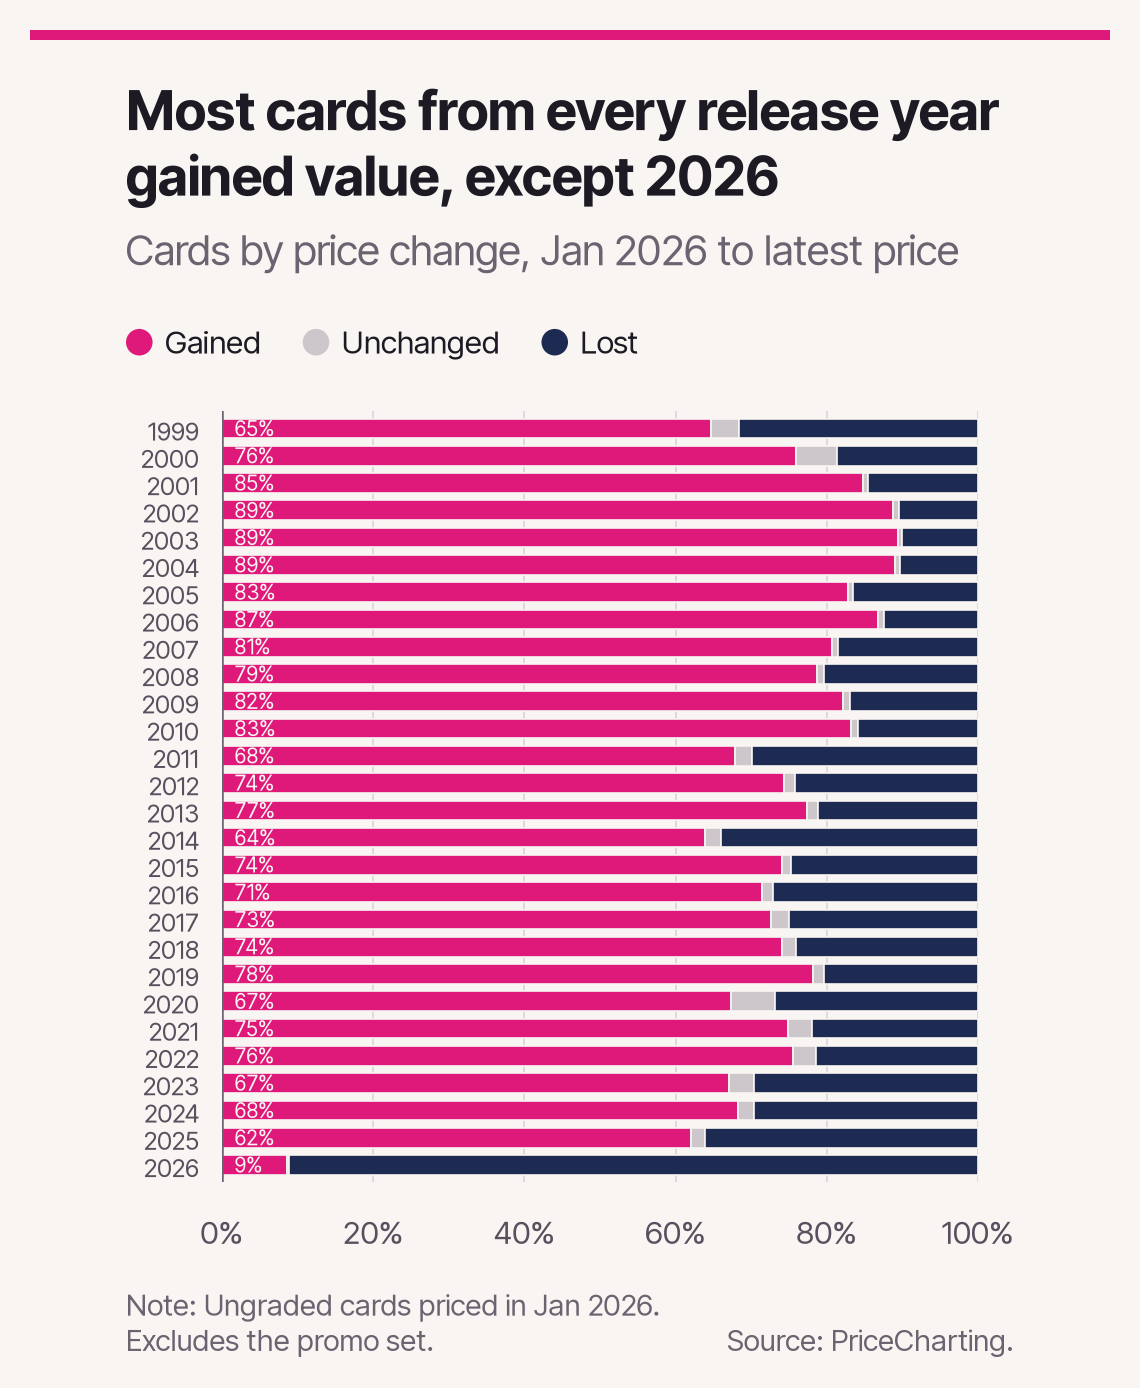

In [13]:
# ===============================
# gained or lost value: by release year
# ===============================
# every card in the promo set shares one release date (2016), so it can't be split by year
year_changes = ungraded_changes[~ungraded_changes["promo"]].copy()
year_changes["release_year"] = year_changes["release_date"].dt.year.astype(str)

change_chart(
    year_changes, "release_year", sorted(year_changes["release_year"].unique()),
    "Most cards from every release year gained value, except 2026",
    f"Note: {GRADE} cards priced in Jan 2026. Excludes the promo set.",
    "change_by_release_year.png",
    labelsize=6,
)

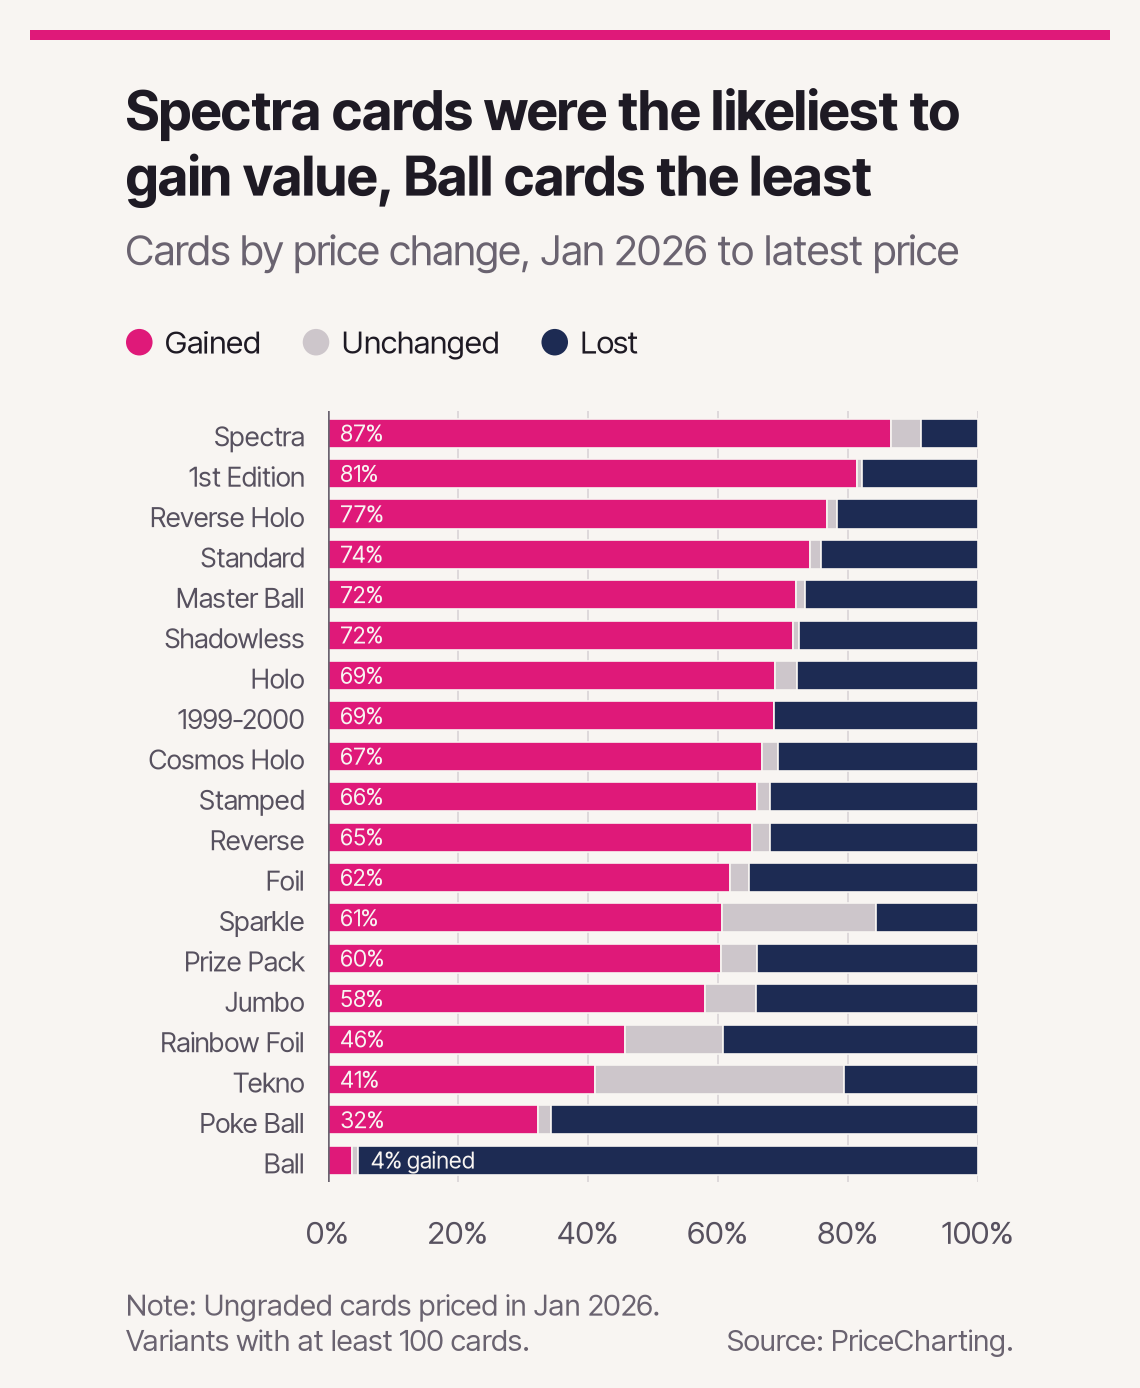

In [14]:
# ===============================
# gained or lost value: by variant
# ===============================
variant_cards = ungraded_changes["variant"].value_counts()
big_variants = variant_cards[variant_cards >= MIN_VARIANT_CARDS].index
gained_share = (
    ungraded_changes[ungraded_changes["variant"].isin(big_variants)]
    .assign(gained=lambda d: d["change"] == "Gained")
    .groupby("variant")["gained"]
    .mean()
    .sort_values(ascending=False)
)

change_chart(
    ungraded_changes, "variant", gained_share.index.tolist(),
    f"{gained_share.index[0]} cards were the likeliest to gain value, {gained_share.index[-1]} cards the least",
    f"Note: {GRADE} cards priced in Jan 2026. Variants with at least {MIN_VARIANT_CARDS} cards.",
    "change_by_variant.png",
    labelsize=6.5,
)

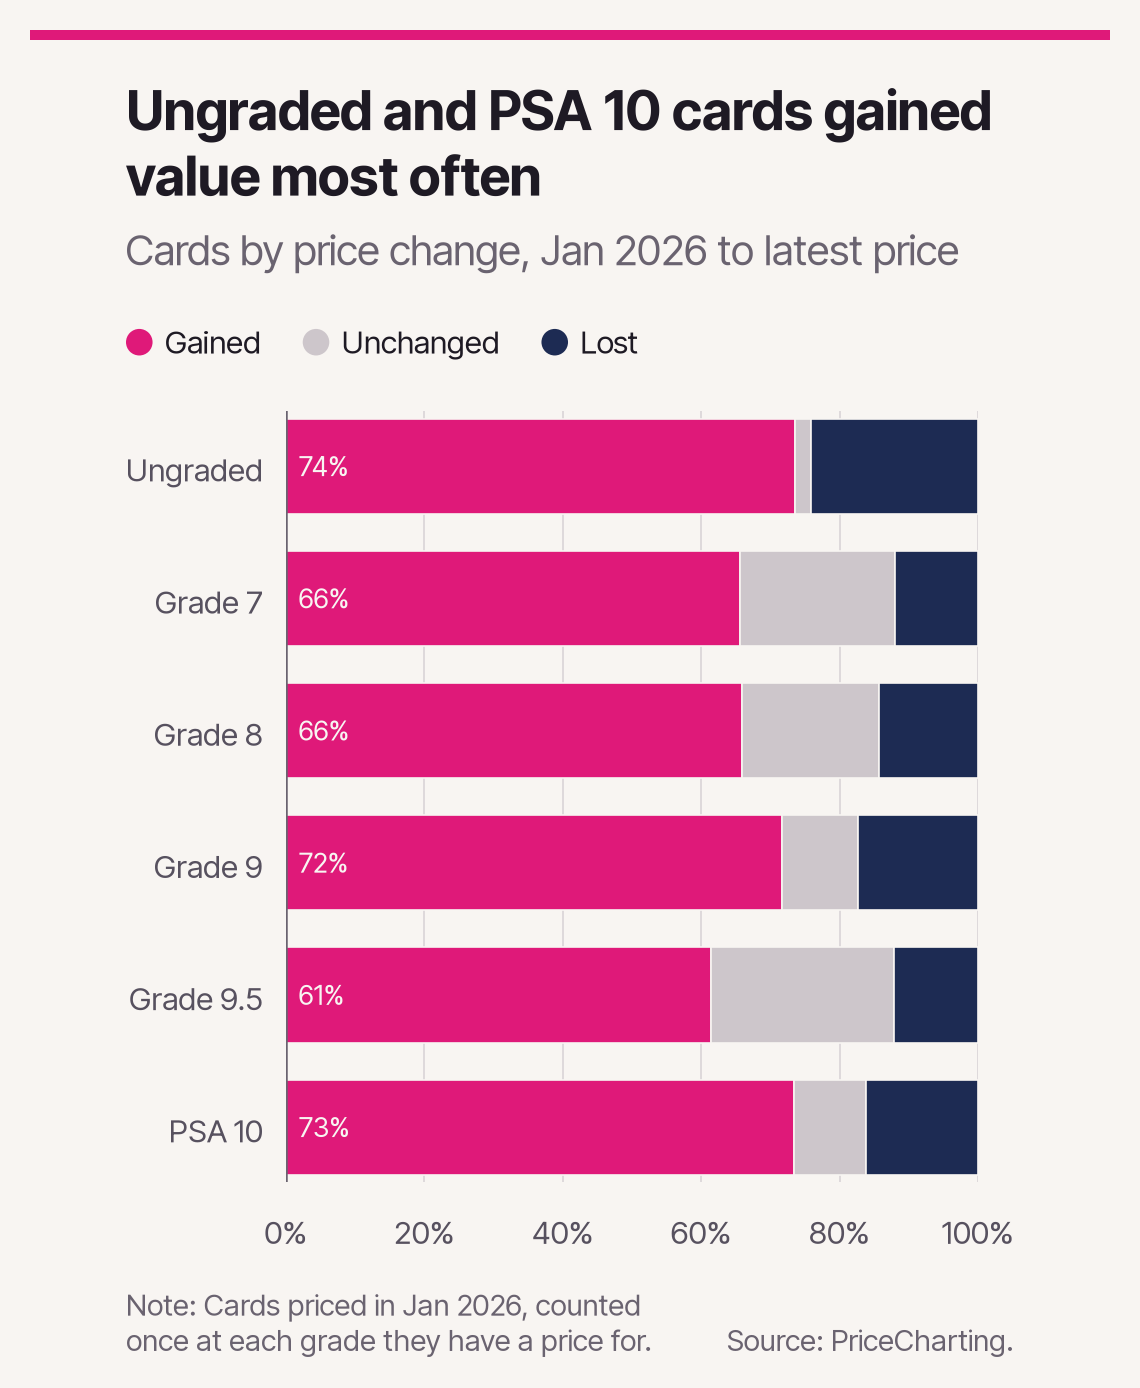

In [15]:
# ===============================
# gained or lost value: by grade
# ===============================
change_chart(
    changes, "grade", GRADE_ORDER,
    "Ungraded and PSA 10 cards gained value most often",
    "Note: Cards priced in Jan 2026, counted once at each grade they have a price for.",
    "change_by_grade.png",
)